In [8]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
from typing import Callable, Tuple

Figura B.1: Simulación Monte Carlo de las trayectorias de un proceso de Wiener estándar y envolventes de dispersión gaussiana.

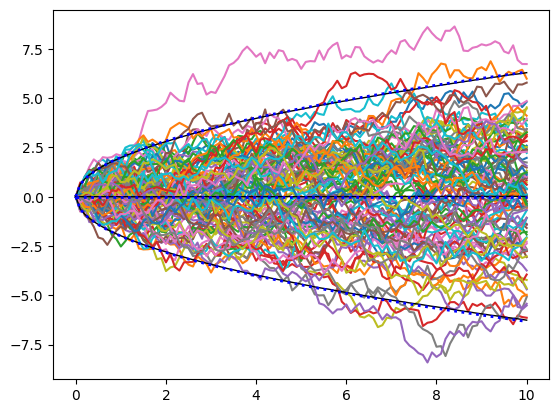

In [18]:
T = 10.0
t_0 = 0.0
N = 100
n_times = N+1
M = 50000 
dT = T / N
times = np.linspace(t_0, t_0 +T, n_times)
rng = np.random.default_rng(seed=123)

W = np.zeros((M, N +1))
W[:,1:] = np.sqrt(dT) * rng.standard_normal((M,N))
W = np.cumsum(W, axis=1)

n_trayectories_plot = np.minimum(M,100)
fig, ax = plt.subplots()
_ = ax.plot(times, W[:n_trayectories_plot, :].T) 

mean_T = np.mean(W, axis = 0)
stdev_T = np.std(W, axis = 0)

mean_theorical = np.zeros_like(times)
stdev_theorical = np.sqrt(times)

alpha = 2

_ = ax.plot(times, mean_T, linewidth =1, color = 'black') 
_ = ax.plot(times, mean_theorical, linestyle = ':', linewidth =2, color = 'blue') 

_ = ax.plot(times, mean_T+alpha*stdev_T, linewidth =1, color = 'black') 
_ = ax.plot(times, mean_theorical+alpha*stdev_theorical, linestyle = ':', linewidth =2, color = 'blue') 

_ = ax.plot(times, mean_T-alpha*stdev_T, linewidth =1, color = 'black') 
_ = ax.plot(times, mean_theorical-alpha*stdev_theorical, linestyle = ':', linewidth =2, color = 'blue')

Figura B.2: Simulación Monte Carlo de las trayectorias de un proceso Ornstein-Uhlenbeck condicionado.

In [6]:
def simulate_conditional_gp(
    t: np.ndarray,
    t_obs: np.ndarray,
    x_obs: np.ndarray,
    mean_fn: Callable[[np.ndarray], np.ndarray],
    kernel_fn: Callable[[np.ndarray], np.ndarray],
    M: int,
) -> np.ndarray:
    """Simulate a Gaussian process conditined to observed values.
        X(t) ~ GP(mean_fn,kernel_fn)
        condition to having observed  X(t_obs) = x_obs at t_obs

    Parameters
    ----------
    t :
        Times at which the process is monitored.

    t_obs :
        Times at which the values of the process have been observed.
        The Gaussian process has the value x_obs at t_obs.

    x_obs :
        Values of the process at t_obs.

    mean_fn :
        Mean function of the Gaussian process [vectorized].

    kernel_fn :
        Covariance functions of the Gaussian process.

    M :
        Number of trajectories in the simulation.

    Returns
    -------
    X:
        Simulated trajectories as an np.ndarray with M rows and len(t) columns.
        Each trajectory is a row of the matrix consisting of the
        values of the process for each value of t.

    mean_vector:
        Vector with the values of the mean for each value of t.
        It is a np.ndarray with len(t) columns.

    kernel_matrix:
        Kernel matrix as an np.ndarray with len(t) rows and len(t)  columns.

    """

    A1, A2 = np.meshgrid(t, t, indexing='ij')
    kernel_11 = kernel_fn(A1, A2)
    B1, B2 = np.meshgrid(t, t_obs, indexing='ij')
    kernel_12 = kernel_fn(B1, B2)
    C1, C2 = np.meshgrid(t_obs, t, indexing='ij')
    kernel_21 = kernel_fn(C1, C2)
    D1, D2 = np.meshgrid(t_obs, t_obs, indexing='ij')
    kernel_22 = kernel_fn(D1, D2)
    mean_1 = mean_fn(t)
    mean_2 = mean_fn(t_obs)

    mean_vector = mean_1 + kernel_12 @ np.linalg.inv(kernel_22) @ (x_obs - mean_2)
    kernel_matrix = kernel_11 - kernel_12 @ np.linalg.inv(kernel_22) @ kernel_21

    rng = np.random.default_rng()
    X = rng.multivariate_normal(mean=mean_vector,cov=kernel_matrix,size=M,method='svd')

    return X, mean_vector, kernel_matrix

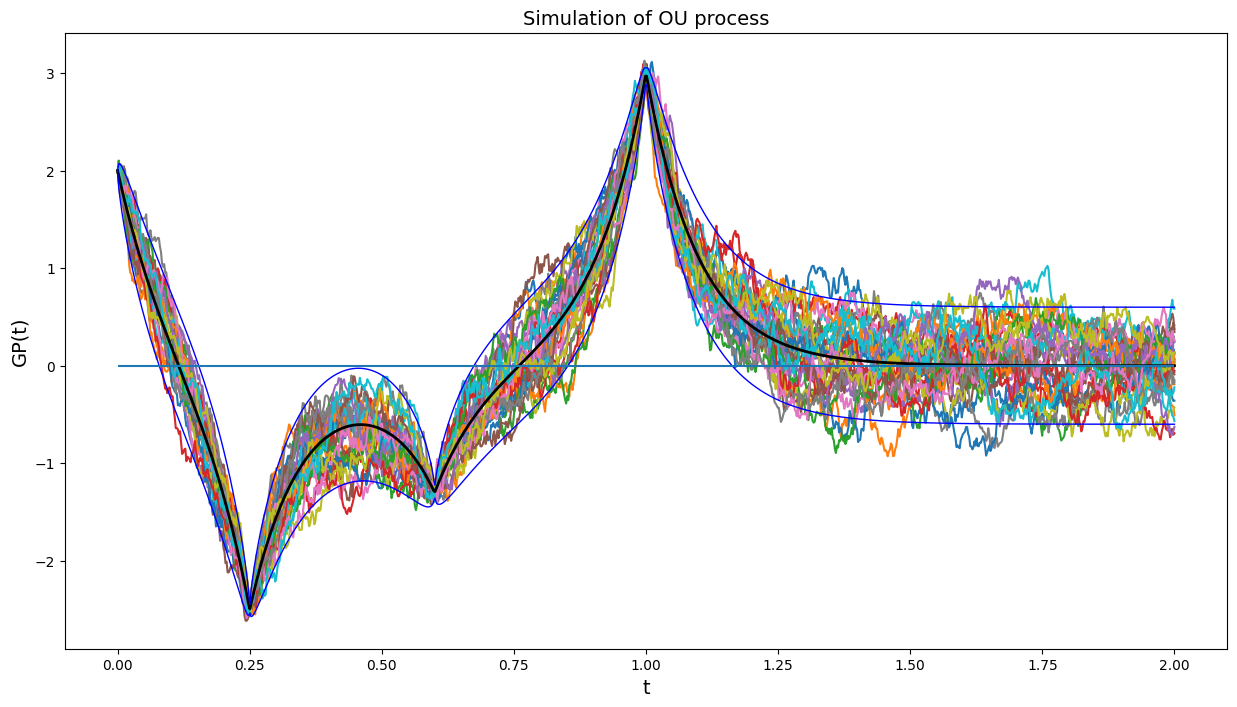

In [10]:
def mean_fn(t, mu=1.0):  
    return np.zeros(np.shape(t))

def kernel_fn(s,t, sigma=0.3, gamma=0.1): 
    return sigma**2*np.exp(- np.abs(s-t) / gamma)

M = 30
t0, t1 = (0.0, 2.0)
N = 1000
t = np.linspace(t0, t1, N)

t_obs = np.array([0.0, 0.25, 0.6, 1.0])
x_obs = np.array([2.0, -2.5, -1.3, 3.0])

X, mean_vector, kernel_matrix = simulate_conditional_gp(t, t_obs,  x_obs, mean_fn,  kernel_fn, M)

n_plot = 30
fontsize = 14
fig, ax = plt.subplots(1, 1, figsize=(15,8))
_ = ax.plot(t, X[:n_plot,:].T)
_ = ax.plot(t, mean_vector, color='k', linewidth=2)
a = 2.0
std_vector = np.sqrt(np.diag(kernel_matrix))
_ = ax.plot(t, mean_vector - a*std_vector, t, mean_vector + a*std_vector, color = 'b', linewidth = 1)
_ = ax.hlines(0.0, t.min(), t.max())
_ = ax.set_xlabel('t', fontsize=fontsize)
_ = ax.set_ylabel('GP(t)', fontsize=fontsize) 
_ = ax.set_title('Simulation of OU process', fontsize=fontsize) 